<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 6 — Approximation Methods: Figures
| Fig | Content |
|-----|--------|
| 01 | Variational $E[\alpha]$ vs Gaussian width: HO and anharmonic |
| 02 | WKB wavefunction in a double-well potential |
| 03 | WKB tunnelling: exact vs WKB; Gamow $\alpha$-decay |
| 04 | Airy functions $\mathrm{Ai}(z)$, $\mathrm{Bi}(z)$ and WKB asymptotics |
| 05 | Berry phase: loop on $\mathbf{B}$-sphere, $\gamma$ vs solid angle |
| 06 | Born-Oppenheimer: H$_2^+$ bonding/antibonding surfaces, LCAO orbitals |


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import airy
from scipy.integrate import quad
import os

plt.rcParams.update({
    'figure.facecolor':'#1e1e2e','axes.facecolor':'#1e1e2e',
    'text.color':'#cdd6f4','axes.labelcolor':'#cdd6f4',
    'xtick.color':'#cdd6f4','ytick.color':'#cdd6f4',
    'axes.edgecolor':'#45475a','grid.color':'#313244',
    'font.family':'DejaVu Sans','font.size':12,
    'axes.titlesize':13,'axes.titleweight':'bold',
    'mathtext.fontset':'cm',
})
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'; BG='#1e1e2e'
os.makedirs('figures/ch06', exist_ok=True)
SAVE = lambda n: plt.savefig(f'figures/ch06/{n}', dpi=150,
                              bbox_inches='tight', facecolor=BG)
print('Setup complete.')


Setup complete.


## Fig 01 — Variational Energy

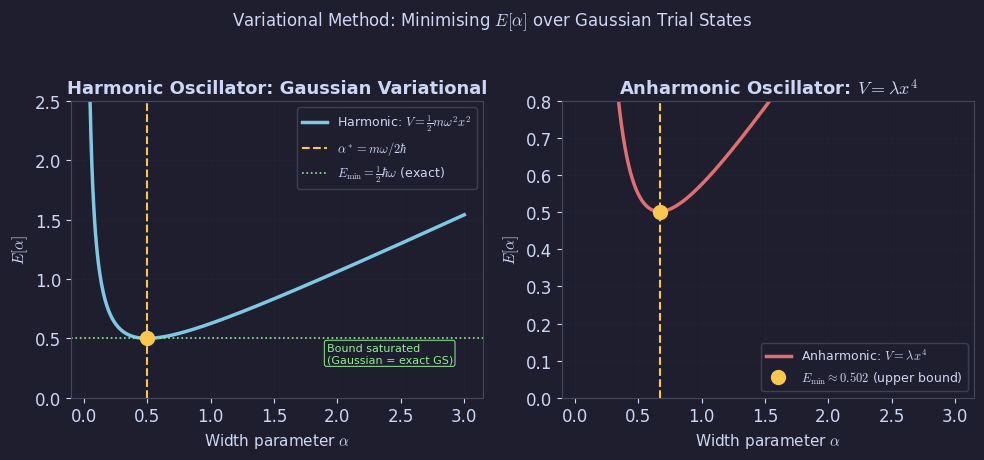

Fig 01 saved.


In [2]:

# Fig 01: Variational energy E[alpha] vs Gaussian width parameter alpha
# Harmonic oscillator (exact min) and anharmonic (approximate min)
# E[alpha] = hbar^2*alpha/(2m) + <V>[alpha]

hbar=1.; m=1.; omega=1.
alpha = np.linspace(0.05, 3.0, 400)

# Harmonic oscillator: V = 0.5*m*omega^2*x^2
# <T> = hbar^2*alpha/(2m), <V> = m*omega^2/(8*alpha)
E_ho = hbar**2*alpha/(2*m) + m*omega**2/(8*alpha)
alpha_min_ho = m*omega/(2*hbar)   # = 0.5
E_min_ho = 0.5*hbar*omega          # = 0.5 (exact)

# Anharmonic: V = lambda*x^4, lambda=0.1
# <x^4> with psi ~ exp(-alpha x^2): 3/(16*alpha^2)
lam = 0.1
E_anh = hbar**2*alpha/(2*m) + lam*3/(16*alpha**2)
alpha_min_anh = np.argmin(E_anh)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.plot(alpha, E_ho, color=BLUE, lw=2.5, label=r'Harmonic: $V=\frac{1}{2}m\omega^2x^2$')
ax.axvline(alpha_min_ho, color=YELLOW, lw=1.5, ls='--',
           label=r'$\alpha^*=m\omega/2\hbar$')
ax.axhline(E_min_ho, color=GREEN, lw=1.2, ls=':',
           label=r'$E_{\min}=\frac{1}{2}\hbar\omega$ (exact)')
ax.plot(alpha_min_ho, E_min_ho, 'o', color=YELLOW, ms=10, zorder=5)
ax.set_xlabel(r'Width parameter $\alpha$', fontsize=11)
ax.set_ylabel(r'$E[\alpha]$', fontsize=11)
ax.set_title('Harmonic Oscillator: Gaussian Variational', color='#cdd6f4')
ax.set_ylim(0, 2.5)
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)
ax.text(0.62, 0.12, 'Bound saturated\n(Gaussian = exact GS)',
        transform=ax.transAxes, color=GREEN, fontsize=8,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, lw=0.7))

ax2 = axes[1]
ax2.plot(alpha, E_anh, color=RED, lw=2.5, label=r'Anharmonic: $V=\lambda x^4$')
idx_min = np.argmin(E_anh)
ax2.plot(alpha[idx_min], E_anh[idx_min], 'o', color=YELLOW, ms=10, zorder=5,
         label=f'$E_{{\\rm min}}\\approx{E_anh[idx_min]:.3f}$ (upper bound)')
ax2.axvline(alpha[idx_min], color=YELLOW, lw=1.5, ls='--')
ax2.set_xlabel(r'Width parameter $\alpha$', fontsize=11)
ax2.set_ylabel(r'$E[\alpha]$', fontsize=11)
ax2.set_title(r'Anharmonic Oscillator: $V=\lambda x^4$', color='#cdd6f4')
ax2.set_ylim(0, 0.8)
ax2.axhline(0.3102, color=GREEN, lw=1.2, ls=':', label=r'exact $E_0\approx0.310$')
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle(r'Variational Method: Minimising $E[\alpha]$ over Gaussian Trial States',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig01_variational.png'); plt.show(); print('Fig 01 saved.')


## Fig 02 — WKB Wavefunction

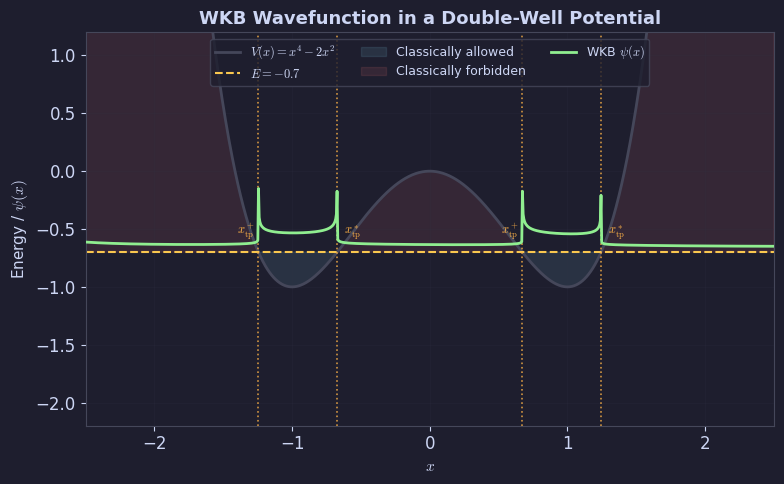

Fig 02 saved.


In [3]:

# Fig 02: WKB wavefunction in a potential well
# Shows oscillatory (allowed) and evanescent (forbidden) regions
# Potential: V(x) = x^4 - 2x^2 (double well), energy E = -0.5

x = np.linspace(-2.5, 2.5, 1000)
V = x**4 - 2*x**2
E = -0.7   # energy level

# Classically allowed: E > V(x), i.e. E - V > 0
allowed  = E - V
p_sq     = np.where(allowed > 0, allowed, 0.0)   # p^2 ~ E-V (hbar=2m=1)
kappa_sq = np.where(allowed < 0, -allowed, 0.0)

# WKB amplitude ~ 1/sqrt(p) in allowed, 1/sqrt(kappa) in forbidden
# Build piecewise WKB wavefunction
p_arr    = np.sqrt(np.maximum(p_sq, 1e-8))
kappa_arr= np.sqrt(np.maximum(kappa_sq, 1e-8))

# Integrate phase
dx = x[1]-x[0]
phi = np.cumsum(p_arr)*dx    # phase integral

psi_wkb = np.zeros_like(x)
in_allowed = allowed > 1e-4
psi_wkb[in_allowed]  = (1.0/np.sqrt(p_arr[in_allowed])) * np.cos(phi[in_allowed] - phi[in_allowed][0])
psi_wkb[~in_allowed] = (1.0/np.sqrt(kappa_arr[~in_allowed])) * np.exp(-np.cumsum(kappa_arr*dx)[~in_allowed]*0.5)
# Normalise
psi_wkb /= np.max(np.abs(psi_wkb)+1e-12) * 2

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, V, color='#45475a', lw=2., label=r'$V(x)=x^4-2x^2$', zorder=2)
ax.axhline(E, color=YELLOW, lw=1.5, ls='--', label=f'$E={E}$', zorder=2)

# Shade regions
ax.fill_between(x, E, V, where=(V < E), color=BLUE, alpha=0.12,
                label='Classically allowed')
ax.fill_between(x, E, V, where=(V > E), color=RED, alpha=0.12,
                label='Classically forbidden')

# WKB wavefunction (shifted up by E for display)
ax.plot(x, psi_wkb + E + 0.05, color=GREEN, lw=2.0,
        label='WKB $\\psi(x)$', zorder=4)

# Turning point markers
tp_idx = np.where(np.diff(np.sign(allowed)))[0]
for k, i in enumerate(tp_idx):
    ax.axvline(x[i], color=ORANGE, lw=1.2, ls=':', alpha=0.8)
    if k in [0, 2]:
        ax.text(x[i]-0.15, E+0.15, r'$x_{\rm tp}^+$', color=ORANGE, fontsize=9)
    else:
        ax.text(x[i]+0.05, E+0.15, r'$x_{\rm tp}^*$', color=ORANGE, fontsize=9)

ax.set_xlabel(r'$x$', fontsize=11)
ax.set_ylabel(r'Energy / $\psi(x)$', fontsize=11)
ax.set_title('WKB Wavefunction in a Double-Well Potential', color='#cdd6f4')
ax.set_ylim(-2.2, 1.2)
ax.set_xlim(-2.5, 2.5)
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4',
          loc='upper center', ncol=3)
ax.grid(True, alpha=0.2)

plt.tight_layout()
SAVE('fig02_wkb.png'); plt.show(); print('Fig 02 saved.')


## Fig 03 — WKB Tunnelling

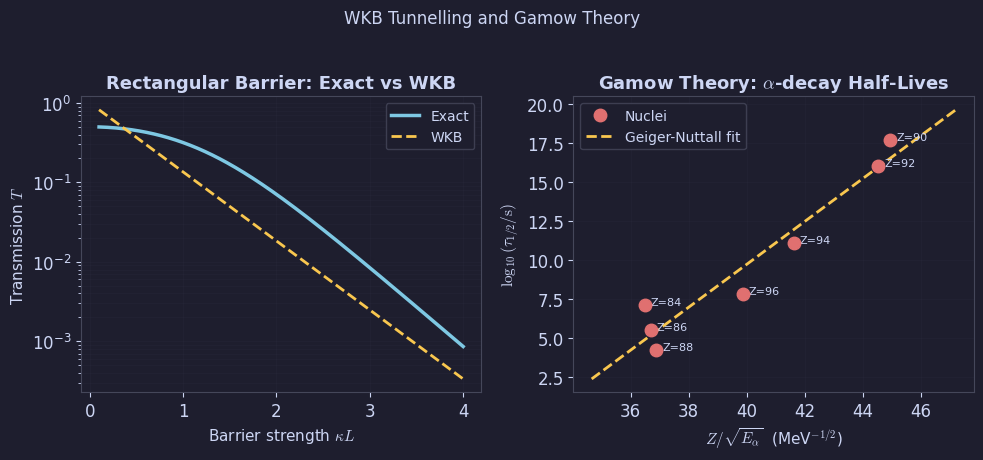

Fig 03 saved.


In [4]:

# Fig 03: WKB tunnelling
# Left: transmission vs barrier height (rectangular, exact vs WKB)
# Right: Gamow alpha-decay — log half-life vs 1/sqrt(E_alpha)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Left: rectangular barrier T vs kappa*L (barrier strength)
hbar=1.; m=1.; L=2.0
kappa_L = np.linspace(0.1, 4.0, 300)
kappa    = kappa_L / L

# Exact T for rectangular barrier
def T_exact(kappa_val, k_val=1.0, L_val=2.0):
    kL = kappa_val*L_val
    return 1.0/(1 + (kappa_val**2+k_val**2)**2/(4*k_val**2*kappa_val**2)*np.sinh(kL)**2)

# WKB: T_wkb = exp(-2*kappa*L)
T_wkb  = np.exp(-2*kappa_L)
T_exact_arr = np.array([T_exact(k) for k in kappa])

ax = axes[0]
ax.semilogy(kappa_L, T_exact_arr, color=BLUE,   lw=2.5, label='Exact')
ax.semilogy(kappa_L, T_wkb,       color=YELLOW, lw=2.0, ls='--', label='WKB')
ax.set_xlabel(r'Barrier strength $\kappa L$', fontsize=11)
ax.set_ylabel(r'Transmission $T$', fontsize=11)
ax.set_title('Rectangular Barrier: Exact vs WKB', color='#cdd6f4')
ax.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2, which='both')

# Right: Gamow theory — log(tau) vs Z/sqrt(E)
# log(tau) ~ a + b*Z/sqrt(E_alpha) (Geiger-Nuttall law)
# Use data-like points for various nuclei
Z_vals = np.array([84, 86, 88, 90, 92, 94, 96])
E_MeV  = np.array([5.3, 5.49, 5.69, 4.01, 4.27, 5.1, 5.8])  # typical Q-values
log_t  = np.array([7.1, 5.5, 4.2, 17.7, 16.0, 11.1, 7.8])    # log10(tau/s) approximate
# Geiger-Nuttall: log(tau) ~ a*Z/sqrt(E) + b
GN_x = Z_vals / np.sqrt(E_MeV)
# Fit line
coeffs = np.polyfit(GN_x, log_t, 1)
xfit   = np.linspace(GN_x.min()*0.95, GN_x.max()*1.05, 100)

ax2 = axes[1]
ax2.plot(GN_x, log_t, 'o', color=RED, ms=9, zorder=5, label='Nuclei')
ax2.plot(xfit, np.polyval(coeffs, xfit), color=YELLOW, lw=2.0, ls='--',
         label='Geiger-Nuttall fit')
for i,(x_,y_,Z_) in enumerate(zip(GN_x, log_t, Z_vals)):
    ax2.text(x_+0.2, y_, f'Z={Z_}', color='#cdd6f4', fontsize=8)
ax2.set_xlabel(r'$Z/\sqrt{E_\alpha}$  (MeV$^{-1/2}$)', fontsize=11)
ax2.set_ylabel(r'$\log_{10}(\tau_{1/2}/{\rm s})$', fontsize=11)
ax2.set_title(r'Gamow Theory: $\alpha$-decay Half-Lives', color='#cdd6f4')
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)

plt.suptitle('WKB Tunnelling and Gamow Theory', color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig03_tunnelling.png'); plt.show(); print('Fig 03 saved.')


## Fig 04 — Airy Functions

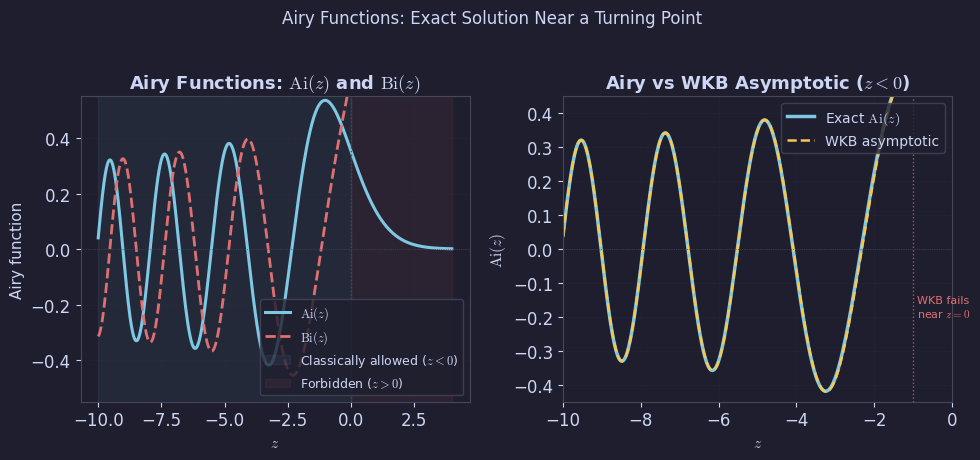

Fig 04 saved.


In [5]:

# Fig 04: Airy functions Ai(z) and Bi(z)
# scipy.special.airy returns (Ai, Ai', Bi, Bi')
from scipy.special import airy as scipy_airy

z = np.linspace(-10, 4, 600)
Ai, Aip, Bi, Bip = scipy_airy(z)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

ax = axes[0]
ax.plot(z, Ai,  color=BLUE,   lw=2.2, label=r'$\mathrm{Ai}(z)$')
ax.plot(z, Bi,  color=RED,    lw=2.0, ls='--', label=r'$\mathrm{Bi}(z)$')
ax.axvline(0, color='#45475a', lw=1., ls=':')
ax.axhline(0, color='#45475a', lw=0.6, ls=':')
ax.fill_betweenx([-0.6, 0.6], -10, 0, color=BLUE, alpha=0.07,
                  label='Classically allowed ($z<0$)')
ax.fill_betweenx([-0.6, 0.6], 0, 4,  color=RED,  alpha=0.07,
                  label='Forbidden ($z>0$)')
ax.set_ylim(-0.55, 0.55)
ax.set_xlabel(r'$z$', fontsize=11)
ax.set_ylabel(r'Airy function', fontsize=11)
ax.set_title('Airy Functions: $\\mathrm{Ai}(z)$ and $\\mathrm{Bi}(z)$', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Right: WKB asymptotics vs exact Ai(z)
z_neg = np.linspace(-10, -0.5, 400)
Ai_neg, _, _, _ = scipy_airy(z_neg)
# WKB asymptotic for z -> -inf: Ai ~ 1/(sqrt(pi)*(-z)^(1/4)) * cos(2/3*(-z)^(3/2) - pi/4)
Ai_wkb = 1.0/(np.sqrt(np.pi)*(-z_neg)**0.25) * np.cos(2.0/3*(-z_neg)**1.5 - np.pi/4)

ax2 = axes[1]
ax2.plot(z_neg, Ai_neg, color=BLUE,   lw=2.5, label=r'Exact $\mathrm{Ai}(z)$')
ax2.plot(z_neg, Ai_wkb, color=YELLOW, lw=1.8, ls='--',
         label=r'WKB asymptotic')
ax2.set_xlim(-10, 0)
ax2.set_ylim(-0.45, 0.45)
ax2.axhline(0, color='#45475a', lw=0.6, ls=':')
ax2.set_xlabel(r'$z$', fontsize=11)
ax2.set_ylabel(r'$\mathrm{Ai}(z)$', fontsize=11)
ax2.set_title('Airy vs WKB Asymptotic ($z<0$)', color='#cdd6f4')
ax2.legend(fontsize=10, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.grid(True, alpha=0.2)
# Annotate where WKB breaks down
ax2.axvline(-1, color=RED, lw=1., ls=':', alpha=0.7)
ax2.text(-0.9, -0.2, 'WKB fails\nnear $z=0$', color=RED, fontsize=8)

plt.suptitle('Airy Functions: Exact Solution Near a Turning Point',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig04_airy.png'); plt.show(); print('Fig 04 saved.')


## Fig 05 — Berry Phase

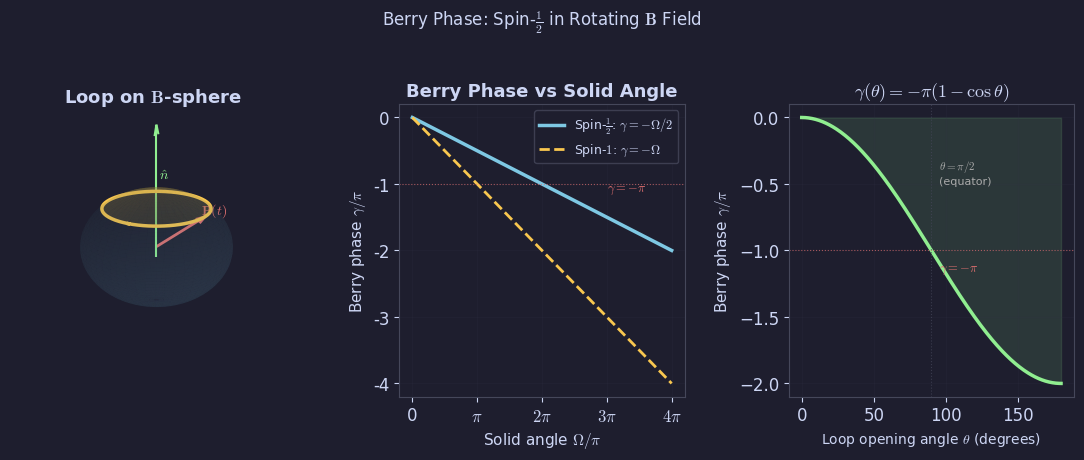

Fig 05 saved.


In [6]:

# Fig 05: Berry phase for spin-1/2 in rotating B field
# Parameter space = sphere (theta, phi)
# Berry phase = -Omega/2 where Omega = solid angle enclosed
# Also show: Berry phase vs solid angle, and AB effect analogy

from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(11, 4.5))

# Left: sphere with closed loop
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax1.set_facecolor(BG)

phi_s = np.linspace(0, 2*np.pi, 200)
theta_s = np.linspace(0, np.pi, 100)
PHI, THETA = np.meshgrid(phi_s, theta_s)
xs = np.sin(THETA)*np.cos(PHI)
ys = np.sin(THETA)*np.sin(PHI)
zs = np.cos(THETA)
ax1.plot_surface(xs, ys, zs, alpha=0.08, color=BLUE, linewidth=0)

# A closed loop at theta=pi/4
theta_loop = np.pi/4
phi_loop   = np.linspace(0, 2*np.pi, 200)
xl = np.sin(theta_loop)*np.cos(phi_loop)
yl = np.sin(theta_loop)*np.sin(phi_loop)
zl = np.cos(theta_loop)*np.ones_like(phi_loop)
ax1.plot(xl, yl, zl, color=YELLOW, lw=2.5, zorder=5)
ax1.quiver(0,0,0, xl[50], yl[50], zl[50],
           color=RED, lw=2., arrow_length_ratio=0.15)
ax1.text(xl[50]+0.1, yl[50], zl[50]+0.1,
         r'$\mathbf{B}(t)$', color=RED, fontsize=10)
ax1.quiver(0,0,-0.2,0,0,2.4,color=GREEN,lw=1.5,arrow_length_ratio=0.08)
ax1.text(0.1,0.1,1.3, r'$\hat{n}$', color=GREEN, fontsize=10)
# Solid angle shading (spherical cap)
theta_cap = np.linspace(0, theta_loop, 40)
phi_cap   = np.linspace(0, 2*np.pi, 40)
TC, PC    = np.meshgrid(theta_cap, phi_cap)
xc=np.sin(TC)*np.cos(PC); yc=np.sin(TC)*np.sin(PC); zc=np.cos(TC)
ax1.plot_surface(xc, yc, zc, alpha=0.25, color=YELLOW)
ax1.set_xlim(-1.2,1.2); ax1.set_ylim(-1.2,1.2); ax1.set_zlim(-1.2,1.2)
ax1.set_axis_off()
ax1.set_title(r'Loop on $\mathbf{B}$-sphere', color='#cdd6f4', pad=2)
ax1.view_init(elev=20, azim=30)

# Middle: Berry phase vs solid angle
ax2 = fig.add_subplot(1, 3, 2)
Omega = np.linspace(0, 4*np.pi, 300)
gamma_half = -Omega/2
gamma_int  = -Omega      # integer spin (for comparison)

ax2.plot(Omega/np.pi, gamma_half/np.pi, color=BLUE,   lw=2.5,
         label=r'Spin-$\frac{1}{2}$: $\gamma=-\Omega/2$')
ax2.plot(Omega/np.pi, gamma_int/np.pi,  color=YELLOW, lw=2.0, ls='--',
         label=r'Spin-$1$: $\gamma=-\Omega$')
ax2.axhline(-1, color=RED, lw=0.8, ls=':', alpha=0.7)
ax2.text(3.0, -1.1, r'$\gamma=-\pi$', color=RED, fontsize=9)
ax2.set_xlabel(r'Solid angle $\Omega/\pi$', fontsize=11)
ax2.set_ylabel(r'Berry phase $\gamma/\pi$', fontsize=11)
ax2.set_title('Berry Phase vs Solid Angle', color='#cdd6f4')
ax2.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax2.set_xticks([0,1,2,3,4]); ax2.set_xticklabels(['0',r'$\pi$',r'$2\pi$',r'$3\pi$',r'$4\pi$'])
ax2.set_yticks([-4,-3,-2,-1,0]); ax2.set_yticklabels(['-4','-3','-2','-1','0'])
ax2.grid(True, alpha=0.2)

# Right: Berry curvature — monopole in B-space for spin-1/2
ax3 = fig.add_subplot(1, 3, 3)
B_arr = np.linspace(-3, 3, 300)
# Berry curvature for spin-1/2: Omega_n = +/- r_hat/(2r^2) -> integrate over sphere = +/-2pi
# Schematic: show Berry phase as function of theta for equatorial loop
theta_v = np.linspace(0, np.pi, 300)
gamma_equator = -(1 - np.cos(theta_v)) * np.pi  # solid angle for cone at angle theta
ax3.plot(np.degrees(theta_v), gamma_equator/np.pi, color=GREEN, lw=2.5)
ax3.axhline(-1, color=RED, lw=0.8, ls=':', alpha=0.7)
ax3.axvline(90, color='#45475a', lw=0.8, ls=':', alpha=0.7)
ax3.fill_between(np.degrees(theta_v), gamma_equator/np.pi, 0,
                 color=GREEN, alpha=0.12)
ax3.text(95, -0.5, r'$\theta=\pi/2$'+'\n(equator)', color='#aaa', fontsize=8)
ax3.text(95, -1.15, r'$\gamma=-\pi$', color=RED, fontsize=9)
ax3.set_xlabel(r'Loop opening angle $\theta$ (degrees)', fontsize=10)
ax3.set_ylabel(r'Berry phase $\gamma/\pi$', fontsize=11)
ax3.set_title(r'$\gamma(\theta) = -\pi(1-\cos\theta)$', color='#cdd6f4')
ax3.grid(True, alpha=0.2)

plt.suptitle(r'Berry Phase: Spin-$\frac{1}{2}$ in Rotating $\mathbf{B}$ Field',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig05_berry_phase.png'); plt.show(); print('Fig 05 saved.')


## Fig 06 — Born-Oppenheimer H$_2^+$

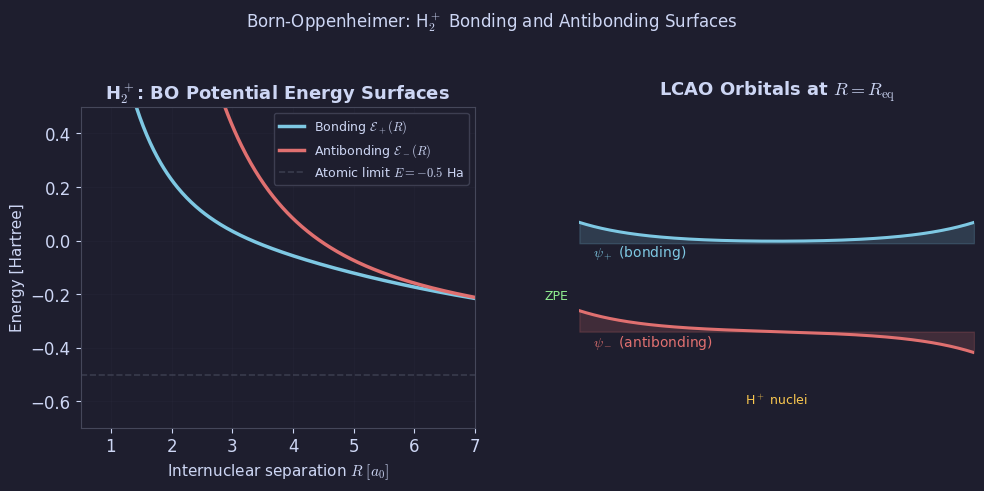

Fig 06 saved.


In [7]:

# Fig 06: Born-Oppenheimer potential energy surfaces for H2+
# Bonding (+) and antibonding (-) LCAO surfaces
# E_+(R) has a minimum (bound state), E_-(R) is purely repulsive
# Using simple analytical approximation with overlap S(R)

a0 = 1.0   # Bohr radius (atomic units, hbar=m=e=1)

R = np.linspace(0.5, 8.0, 400)

# Overlap integral S(R) for 1s hydrogen orbitals
S = np.exp(-R/a0) * (1 + R/a0 + R**2/(3*a0**2))

# Matrix elements (atomic units, E0 = -0.5 Hartree for H)
E0 = -0.5
# Standard LCAO integrals (atomic units):
#   J = <A| -1/r_B |A> = -1/R + exp(-2R) (1 + 1/R)     (Coulomb)
#   K = <A| -1/r_A |B> = -exp(-R) (1 + R)               (exchange)
#   E_pm = E0 + (J pm K)/(1 pm S)   (+ 1/R proton repulsion below)
J = -1.0/R + np.exp(-2*R)*(1 + 1.0/R)
K = -np.exp(-R)*(1 + R)
E_bond     = E0 + (J + K) / (1 + S)
E_antibond = E0 + (J - K) / (1 - S)

# Add proton repulsion
E_pp = 1.0/R
E_bond_total    = E_bond     + E_pp
E_antibond_total= E_antibond + E_pp

# Atomic limit (H + H+, E = -0.5 Hartree)
E_atomic = E0 * np.ones_like(R)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

ax = axes[0]
ax.plot(R, E_bond_total,     color=BLUE,   lw=2.5, label=r'Bonding $\mathcal{E}_+(R)$')
ax.plot(R, E_antibond_total, color=RED,    lw=2.5, label=r'Antibonding $\mathcal{E}_-(R)$')
ax.axhline(E0, color='#45475a', lw=1.2, ls='--', alpha=0.7,
           label=r'Atomic limit $E=-0.5$ Ha')

# Minimum of bonding curve
i_min = np.argmin(E_bond_total)
ax.plot(R[i_min], E_bond_total[i_min], 'o', color=YELLOW, ms=10, zorder=5)
ax.annotate(f'$R_{{\\rm eq}}\\approx{R[i_min]:.1f}\\,a_0$',
            xy=(R[i_min], E_bond_total[i_min]),
            xytext=(R[i_min]+0.8, E_bond_total[i_min]+0.15),
            color=YELLOW, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))

# Zero-point energy schematic
E_min = E_bond_total[i_min]
omega_est = 0.12
ax.annotate('', xy=(R[i_min], E_min+omega_est/2),
            xytext=(R[i_min], E_min),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
ax.text(R[i_min]+0.15, E_min+omega_est/4, 'ZPE', color=GREEN, fontsize=9)

ax.set_xlim(0.5, 7.0); ax.set_ylim(-0.7, 0.5)
ax.set_xlabel(r'Internuclear separation $R\;[a_0]$', fontsize=11)
ax.set_ylabel(r'Energy [Hartree]', fontsize=11)
ax.set_title(r'H$_2^+$: BO Potential Energy Surfaces', color='#cdd6f4')
ax.legend(fontsize=9, facecolor=BG, edgecolor='#45475a', labelcolor='#cdd6f4')
ax.grid(True, alpha=0.2)

# Right: LCAO orbital schematic
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.set_xlim(-3, 3); ax2.set_ylim(-1.5, 2.5)
ax2.axis('off')

x_plot = np.linspace(-3, 3, 300)
R_bond = R[i_min]
# 1s orbitals centred at ±R/2
phi_A = np.exp(-np.abs(x_plot + R_bond/2)/a0)
phi_B = np.exp(-np.abs(x_plot - R_bond/2)/a0)
psi_plus  =  (phi_A + phi_B) / np.sqrt(2*(1+S[i_min]))
psi_minus = (phi_A - phi_B) / np.sqrt(2*(1-S[i_min]))

scale = 1.0
ax2.plot(x_plot, psi_plus*scale + 0.8,  color=BLUE,  lw=2.2,
         label=r'Bonding $\psi_+$')
ax2.plot(x_plot, psi_minus*scale - 0.3, color=RED,   lw=2.2,
         label=r'Antibonding $\psi_-$')
ax2.fill_between(x_plot, 0.8, psi_plus*scale + 0.8,
                 color=BLUE, alpha=0.18)
ax2.fill_between(x_plot, -0.3, psi_minus*scale - 0.3,
                 color=RED, alpha=0.18)

# Nucleus positions
for xn in [-R_bond/2, R_bond/2]:
    ax2.axvline(xn, color=YELLOW, lw=1.2, ls=':', alpha=0.6)
    ax2.plot(xn, -1.0, '^', color=YELLOW, ms=12, zorder=5)
ax2.text(0, -1.2, r'H$^+$ nuclei', ha='center', color=YELLOW, fontsize=9)

ax2.text(-2.8, 0.62, r'$\psi_+$ (bonding)', color=BLUE, fontsize=10)
ax2.text(-2.8, -0.48, r'$\psi_-$ (antibonding)', color=RED, fontsize=10)
ax2.set_title(r'LCAO Orbitals at $R=R_{\rm eq}$', color='#cdd6f4', pad=8)

plt.suptitle(r'Born-Oppenheimer: H$_2^+$ Bonding and Antibonding Surfaces',
             color='#cdd6f4', fontsize=12, y=1.02)
plt.tight_layout()
SAVE('fig06_born_oppenheimer.png'); plt.show(); print('Fig 06 saved.')


---
## ZIP & Download

In [8]:

import shutil, os
z = shutil.make_archive('ch06_figures','zip','figures/ch06')
print(f'ZIP: {z}, {os.path.getsize(z)//1024} KB')
try:
    from google.colab import files
    files.download('ch06_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — ch06_figures.zip in working directory.')


ZIP: /content/ch06_figures.zip, 648 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
